# OLA Ride Insights - Advanced EDA
July 2024 booking data. Charts use matplotlib/seaborn. Every number below is computed in the cell that shows it.

## 1. Project Introduction & 2. Business Problem
OLA generates large volumes of booking data. Goal: understand demand, cancellations, vehicle performance, payments and ratings to support operational decisions.

In [1]:
import sys; sys.path.insert(0, "..") if __import__("os").path.exists("../src") else None
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy import stats
from src import preprocessing as pp
from src.kpi_engine import headline_kpis, vehicle_scorecard, per_weekday_average, iqr_outliers, pareto
sns.set_theme(style="whitegrid", palette=["#FF6A13","#F5A524","#5B9DFF","#3DDC97","#B28DFF","#FF8FB1","#8AD1C2"])
raw_sheets = pd.read_excel(pp.RAW_PATH, sheet_name=None)
for k, v in raw_sheets.items(): print(f"{k:8s} shape={v.shape}")

July     shape=(103024, 20)
Sheet1   shape=(18, 9)
Sheet2   shape=(7, 2)


## 3. Dataset Overview
`July` is the only raw ride-level sheet; `Sheet1` is a pivot summary and `Sheet2` an icon lookup.

In [2]:
raw = pp.load_raw()
print(raw.dtypes.to_string()); raw.head(3)

Date                          datetime64[us]
Time                                  object
Booking_ID                               str
Booking_Status                           str
Customer_ID                              str
Vehicle_Type                             str
Pickup_Location                          str
Drop_Location                            str
V_TAT                                float64
C_TAT                                float64
Canceled_Rides_by_Customer               str
Canceled_Rides_by_Driver                 str
Incomplete_Rides                         str
Incomplete_Rides_Reason                  str
Booking_Value                          int64
Payment_Method                           str
Ride_Distance                          int64
Driver_Ratings                       float64
Customer_Rating                      float64
Vehicle Images                           str


## 4. Data Dictionary
See `documentation/Data_Dictionary.md`. Key rule: ratings, payment, TAT and incomplete flag exist only for Success bookings.

## 5-7. Data Quality, Missing Values, Duplicates

{'original_rows': 103024, 'duplicate_rows': 0, 'duplicate_booking_ids': 0, 'timestamp_time_mismatch': 0, 'invalid_rating_count': 0, 'nonpositive_booking_value': 0, 'negative_distance': 0, 'success_with_zero_distance': 0, 'nonsuccess_with_distance': 0, 'nonsuccess_with_rating': 0, 'status_vs_reason_inconsistent': 0, 'cleaned_rows': 103024, 'rows_removed': 0}
Quality score: 100.0 | 100 x (1 - rule violations / (rows x 9 validity rules))


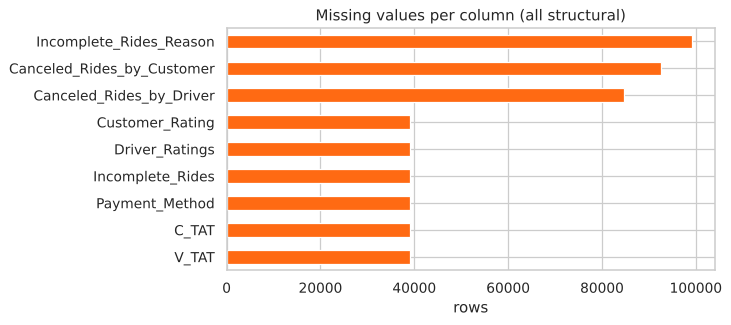

In [3]:
df, audit = pp.clean(raw)
print({k: v for k, v in audit.items() if isinstance(v, int)})
print("Quality score:", audit["data_quality_score"], "|", audit["data_quality_formula"])
miss = raw.isna().sum(); miss = miss[miss > 0].sort_values()
ax = miss.plot.barh(figsize=(7, 3.5), title="Missing values per column (all structural)"); ax.set_xlabel("rows")

In [4]:
# prove the nulls are structural: every non-success row is null in these columns
nonsucc = raw[raw.Booking_Status != "Success"]
print(nonsucc[["V_TAT","C_TAT","Payment_Method","Driver_Ratings","Customer_Rating","Incomplete_Rides"]].isna().all().to_dict())

{'V_TAT': True, 'C_TAT': True, 'Payment_Method': True, 'Driver_Ratings': True, 'Customer_Rating': True, 'Incomplete_Rides': True}


## 8-9. Cleaning & Feature Engineering
No rows removed; 9 validity rules had zero violations. Engineered features are listed in the data dictionary.

In [5]:
print(df.shape); df[["Timestamp","Booking_Hour","Day_Name","Time_Of_Day","Is_Peak_Hour","Status_Category","Revenue_Category","Distance_Category"]].head()

(103024, 40)


## 10. Univariate Analysis

skew of Booking_Value: 2.57


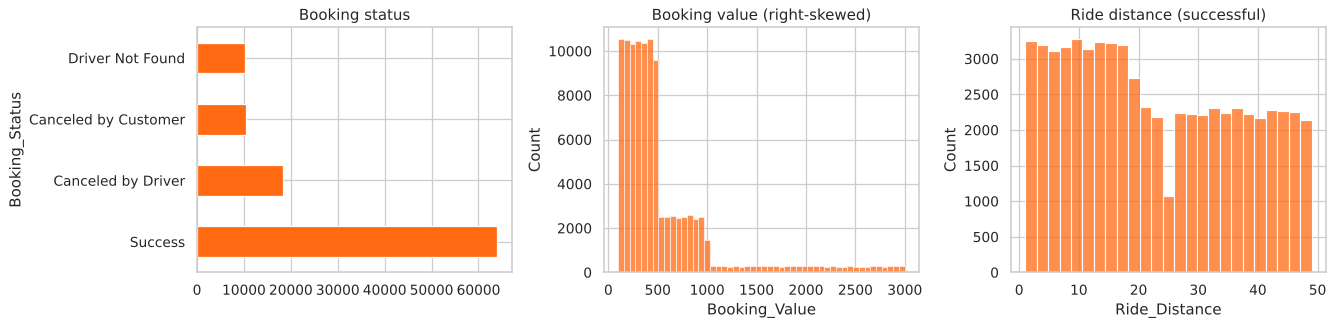

In [6]:
ok = df[df.Is_Success]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
df.Booking_Status.value_counts().plot.barh(ax=ax[0], title="Booking status"); 
sns.histplot(df.Booking_Value, bins=50, ax=ax[1]).set_title("Booking value (right-skewed)")
sns.histplot(ok.Ride_Distance, bins=25, ax=ax[2]).set_title("Ride distance (successful)")
plt.tight_layout(); print("skew of Booking_Value:", round(df.Booking_Value.skew(), 2))

**Reading:** 62% of bookings succeed; value is right-skewed so the median (386) is far below the mean (549).

## 11-12. Bivariate & Multivariate Analysis

Vehicle_Type  total_bookings  success_rate  cancellation_rate  avg_distance  avg_customer_rating
 Prime Sedan           14877        0.6304              0.273       25.0064               4.0016
      E-Bike           14816        0.6196             0.2839       25.1462               3.9879
        Auto           14755        0.6213             0.2832       10.0407               3.9988
  Prime Plus           14707        0.6171             0.2827       25.0343               4.0095
        Bike           14662         0.623             0.2794       24.9339               3.9934
   Prime SUV           14655        0.6139             0.2829       24.8831               3.9994
        Mini           14552        0.6209              0.281       24.9782               3.9977


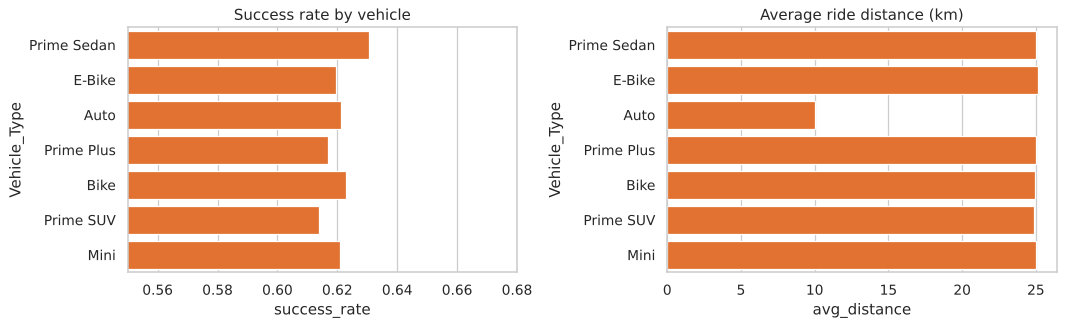

In [7]:
sc = vehicle_scorecard(df); display_cols = ["Vehicle_Type","total_bookings","success_rate","cancellation_rate","avg_distance","avg_customer_rating"]
print(sc[display_cols].round(4).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.barplot(data=sc, y="Vehicle_Type", x="success_rate", ax=ax[0]).set_title("Success rate by vehicle"); ax[0].set_xlim(.55, .68)
sns.barplot(data=sc, y="Vehicle_Type", x="avg_distance", ax=ax[1]).set_title("Average ride distance (km)")
plt.tight_layout()

In [8]:
ct = pd.crosstab(df.Vehicle_Type, df.Is_Success)
chi2, p, *_ = stats.chi2_contingency(ct); print(f"Success vs vehicle: chi2={chi2:.2f}, p={p:.3f} -> differences are not statistically significant at 5%" if p > .05 else f"p={p:.4f}: significant")

Success vs vehicle: chi2=10.15, p=0.119 -> differences are not statistically significant at 5%


## 13. Time-Based Analysis

max-min spread = 5.4% of mean; uniformity chi-square p = 0.74
 Day_Name  avg_bookings_per_day  days_in_window
   Monday                3345.8               5
  Tuesday                3385.2               5
Wednesday                3286.8               5
 Thursday                3309.0               4
   Friday                3336.2               4
 Saturday                3335.2               4
   Sunday                3253.2               4


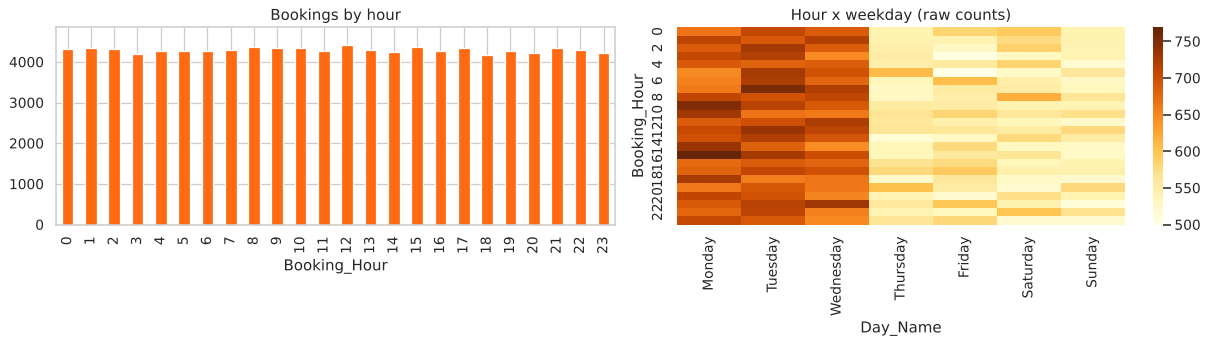

In [9]:
hourly = df.groupby("Booking_Hour").size()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
hourly.plot.bar(ax=ax[0], title="Bookings by hour"); ax[0].set_ylim(0, hourly.max() * 1.1)
m = df.pivot_table(index="Booking_Hour", columns="Day_Name", values="Booking_ID", aggfunc="count")[["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]]
sns.heatmap(m, cmap="YlOrBr", ax=ax[1]).set_title("Hour x weekday (raw counts)"); plt.tight_layout()
print(f"max-min spread = {(hourly.max()-hourly.min())/hourly.mean():.1%} of mean; uniformity chi-square p = {stats.chisquare(hourly)[1]:.2f}")
print(per_weekday_average(df).round(1).to_string(index=False))

**Reading:** Mon-Wed look busier in raw counts only because July 2024 contains five of each; per-day averages are flat. There is no strong daily peak.

## 14. Vehicle Type Analysis

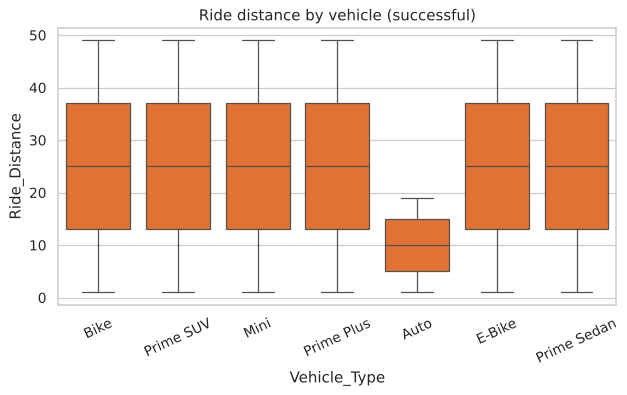

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=ok, x="Vehicle_Type", y="Ride_Distance", ax=ax).set_title("Ride distance by vehicle (successful)"); plt.xticks(rotation=25)

## 15. Revenue Analysis
Total booking value (all statuses) is **not** revenue. Successful value is Success only; fully completed also excludes incomplete rides.

total_booking_value             56,534,614
successful_booking_value        35,080,467
fully_completed_value           32,829,985


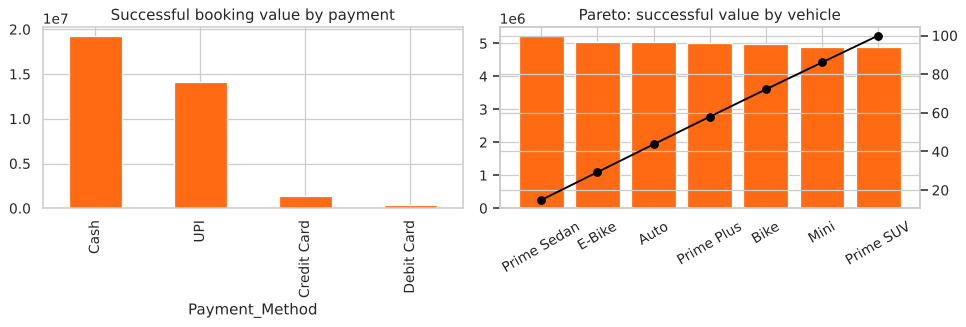

In [11]:
k = headline_kpis(df)
for n in ["total_booking_value","successful_booking_value","fully_completed_value"]: print(f"{n:28s}{k[n]:>14,.0f}")
pay = ok.groupby("Payment_Method").Booking_Value.sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
pay.plot.bar(ax=ax[0], title="Successful booking value by payment"); 
d = pareto(ok.groupby("Vehicle_Type").Booking_Value.sum()); ax[1].bar(d.iloc[:,0], d["value"]); ax2 = ax[1].twinx(); ax2.plot(d.iloc[:,0], d.cum_share*100, color="k", marker="o"); ax[1].set_title("Pareto: successful value by vehicle"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout()

## 16. Cancellation Analysis

{'Driver': 18434, 'Customer': 10499, 'No Driver Found': 10124}
incomplete reasons: {'Customer Demand': 1601, 'Vehicle Breakdown': 1591, 'Other Issue': 734}


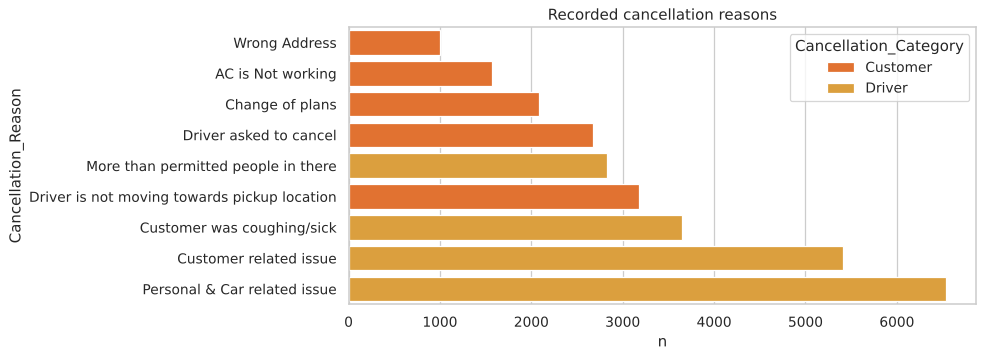

In [12]:
c = df[df.Cancellation_Reason.notna()]
t = c.groupby(["Cancellation_Category","Cancellation_Reason"]).size().rename("n").reset_index().sort_values("n")
fig, ax = plt.subplots(figsize=(9, 4)); sns.barplot(data=t, y="Cancellation_Reason", x="n", hue="Cancellation_Category", dodge=False, ax=ax).set_title("Recorded cancellation reasons")
print(df.Cancellation_Category.value_counts().to_dict()); print("incomplete reasons:", ok.Incomplete_Rides_Reason.value_counts().to_dict())

## 17. Customer Behaviour Analysis

In [13]:
per = df.Customer_ID.value_counts()
print("customers:", len(per), "| booked more than once:", int((per > 1).sum()), f"({(per>1).mean():.1%})", "| max bookings:", per.max())
print(per.value_counts().sort_index().to_string())

customers: 94544 | booked more than once: 7954 (8.4%) | max bookings: 5
count
1    86590
2     7456
3      471
4       26
5        1


## 18-19. Driver Performance & Ratings

corr: -0.0028 | ratings <=3.5: 27.6% / 27.5%
ANOVA customer rating ~ vehicle p = 0.286


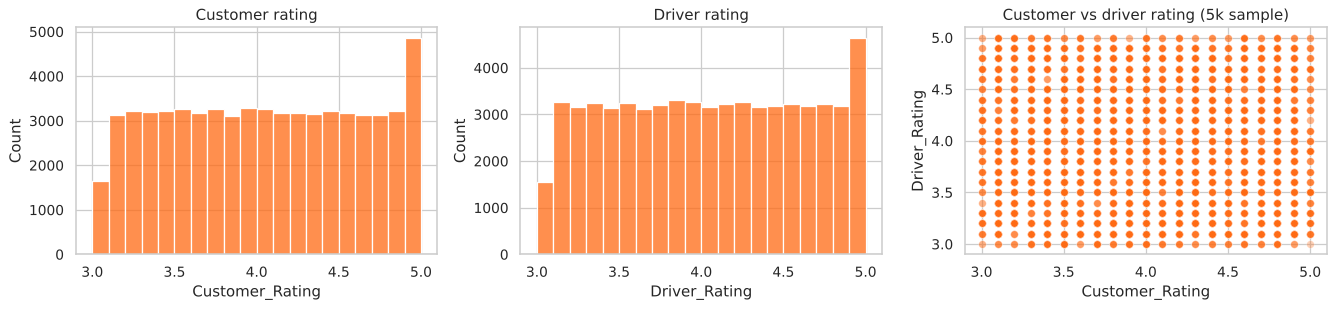

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(ok.Customer_Rating, bins=20, ax=ax[0]).set_title("Customer rating"); sns.histplot(ok.Driver_Rating, bins=20, ax=ax[1]).set_title("Driver rating")
sns.scatterplot(data=ok.sample(5000, random_state=1), x="Customer_Rating", y="Driver_Rating", alpha=.3, ax=ax[2]).set_title("Customer vs driver rating (5k sample)")
plt.tight_layout(); print("corr:", round(ok.Customer_Rating.corr(ok.Driver_Rating), 4), "| ratings <=3.5:", f"{(ok.Customer_Rating<=3.5).mean():.1%} / {(ok.Driver_Rating<=3.5).mean():.1%}")
print("ANOVA customer rating ~ vehicle p =", round(stats.f_oneway(*[g.Customer_Rating for _, g in ok.groupby("Vehicle_Type")])[1], 3))

## 20. Outlier Detection

IQR outliers in Booking_Value within vehicle: 8489 (8.2%) - statistical outliers only, not fraud


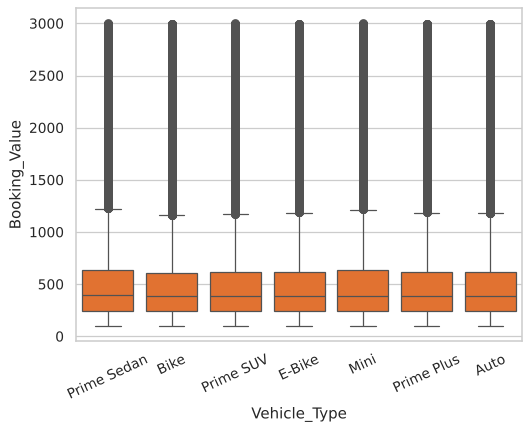

In [15]:
flag = df.groupby("Vehicle_Type").Booking_Value.transform(iqr_outliers)
print("IQR outliers in Booking_Value within vehicle:", int(flag.sum()), f"({flag.mean():.1%}) - statistical outliers only, not fraud")
sns.boxplot(data=df, x="Vehicle_Type", y="Booking_Value"); plt.xticks(rotation=25)

## 21. Correlation Analysis

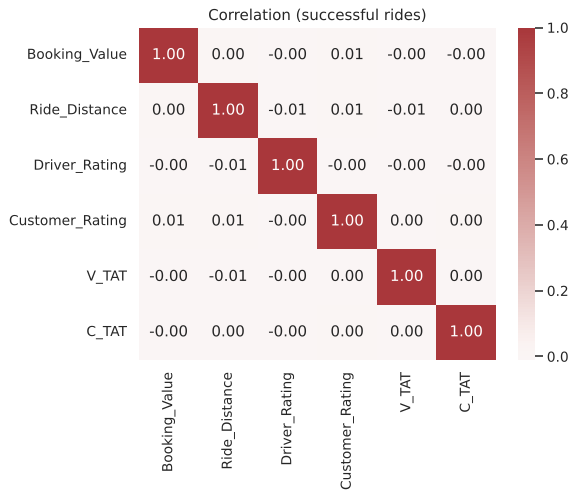

In [16]:
num = ok[["Booking_Value","Ride_Distance","Driver_Rating","Customer_Rating","V_TAT","C_TAT"]]
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="vlag", center=0).set_title("Correlation (successful rides)")

**Reading:** booking value is essentially uncorrelated with distance in this file, which is unusual for ride fares.

## 22. Statistical Analysis
Tests run above: chi-square (success vs vehicle; hourly uniformity), ANOVA (rating vs vehicle), Pearson (ratings).

## 23. Business Insights & 24. Final Recommendations
See `documentation/Business_Insights.md`. Summary: 62.1% success; driver-led cancellations (18,434 vs 10,499); vehicle, hour and rating differences are not statistically significant; fare does not track distance, so treat the dataset as possibly synthetic. Recommendations: investigate driver cancellation causes, reduce the 38% unfulfilled demand, track incomplete-ride causes (breakdown 1,591), collect multi-month and cost data.